# R-KalWeNN no House Prices

Notebook autossuficiente: todos os modelos, codificadores e médias estão
definidos aqui.

O foco é o R-KalWeNN. A Regression WiSARD entra como comparação, e o número
publicado na Tabela 2 do Neurocomputing 416 (2020) entra como referência
externa, revisada por pares.

| seção | conteúdo |
|---|---|
| 1 | configuração: todos os hiperparâmetros num lugar só |
| 2 | definições: thermometer, médias, endereçamento, Regression WiSARD |
| 3 | dados: pipeline do `houseprice.py`, alvo em `log1p` |
| 4 | R-KalWeNN: `c`, `y` e a atualização de cada um |
| 5 | grid search conjunto |
| 6 | resultado contra a referência publicada |

**As duas variantes da seção 4 são independentes e estão em subseções
separadas**, para que a perdedora possa ser apagada sem tocar no resto.

---
# Seção 1 — Configuração

Tudo o que é hiperparâmetro está nesta célula.

In [187]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COR_KAL, COR_REW, COR_REF = "#2F6B6A", "#B4674D", "#8A8F98"

# ── dados ────────────────────────────────────────────────────────────────────
BASE_DADOS   = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"
TEST_SIZE    = 0.33          # houseprice.py
RANDOM_STATE = 0             # houseprice.py

# ── codificação, fixada na configuração vencedora da varredura ───────────────
THERM        = 27            # bits de thermometer por atributo
ADDR         = 6             # bits por RAM node
SEED_MAPPING = 0

# ── referência publicada ─────────────────────────────────────────────────────
# Neurocomputing 416 (2020), Tabela 2: ReW no House Prices, média vencedora
# Median, MAE 0.278 com desvio 0. É o único baseline usado aqui.
REF_ARTIGO = 0.278

# ── estados iniciais, fixos nas duas variantes ───────────────────────────────
X0_C, X0_Y = 0.0, 0.0
SEEDS_GRID = (0, 1, 2)       # ordens de treino avaliadas por configuração

print(f"codificação: thermometer {THERM}, address {ADDR}, mapping seed {SEED_MAPPING}")
print(f"referência publicada (ReW, Median): MAE {REF_ARTIGO}")

codificação: thermometer 27, address 6, mapping seed 0
referência publicada (ReW, Median): MAE 0.278


---
# Seção 2 — Definições

## 2.1 Codificação: `DynamicThermometer`

Porte do `DynamicThermometer` do `wisardpkg`. Cada atributo vira $n$ bits. Os
limiares de um atributo com faixa $[\min, \max]$ são

$$
\tau_j = \min + j\,\frac{\max-\min}{n}, \qquad j = 0,\dots,n-1
$$

e o bit $j$ vale 1 quando $x > \tau_j$. O primeiro limiar é o próprio mínimo,
com comparação estrita, então o valor mínimo do treino gera o vetor todo zero.
Os limiares são acumulados e não calculados por multiplicação, para reproduzir
o mesmo arredondamento do `math::ranges` da referência.

In [188]:
class DynamicThermometer:
    """Termômetro por atributo, com faixa própria para cada um."""

    def __init__(self, sizes, minimos, maximos):
        self.sizes = list(sizes)
        self.limiares = []
        for n, mn, mx in zip(self.sizes, minimos, maximos):
            passo = (mx - mn) / n
            v, faixa = mn, []
            for _ in range(n):                # acumula, como o math::ranges
                faixa.append(v)
                v += passo
            self.limiares.append(np.asarray(faixa, dtype=float))
        self.size = int(np.sum(self.sizes))

    def transform(self, X):
        """(n_amostras, n_atributos) float -> (n_amostras, size) uint8."""
        X = np.atleast_2d(np.asarray(X, dtype=float))
        saida = np.empty((len(X), self.size), dtype=np.uint8)
        k = 0
        for i, faixa in enumerate(self.limiares):
            n = len(faixa)
            saida[:, k:k + n] = (X[:, [i]] > faixa[None, :]).astype(np.uint8)
            k += n
        return saida


print("DynamicThermometer definido")

DynamicThermometer definido


---
## 2.2 As médias

Duas famílias, porque as duas células guardam coisas diferentes.

**Família ReW.** A célula guarda contador $c_k$ e soma $S_k$. A estimativa da
RAM node é $\mu_k = S_k / c_k$, e o contador entra como **denominador**.

| média | fórmula |
|---|---|
| `SimpleMean` | $\sum_k S_k \big/ \sum_k c_k$ |
| `PowerMean(p)` | $\left(\frac{1}{m}\sum \mu_k^{\,p}\right)^{1/p}$ |
| `HarmonicMean` | $m \big/ \sum \mu_k^{-1}$ |
| `HarmonicPower(p)` | $\left(m \big/ \sum \mu_k^{-p}\right)^{1/p}$ |
| `ExponentialMean` | $\log\!\left(\frac{1 + \sum e^{\mu_k}}{m}\right)$ |
| `Median` | valor central dos $\mu_k$, pela fórmula da tese |

$m$ é o número de RAM nodes com $c_k \neq 0$. O `1 +` da `ExponentialMean` está
no código da referência (`double emean = 1`) e é mantido. A `Median` é o porte
do `Median::calculate` do `wisardpkg`, que é o que a tese executou.

**Família R-KalWeNN.** A célula guarda uma confiança $c_k \in [0,1)$ e um valor
esperado $y_k$. O $y_k$ já é a estimativa local, então não há divisão por
contador: o $c_k$ **multiplica** o $y_k$, e a normalização é $\sum c_k$.

O prefixo `K` marca que são as fórmulas ponderadas que desenhamos para o
R-KalWeNN, e não as da Regression WiSARD.

| média | fórmula |
|---|---|
| `K-SimpleMean` | $\dfrac{\sum c_k y_k}{\sum c_k}$ |
| `K-PowerMean(p)` | $\left(\dfrac{\sum c_k y_k^{\,p}}{\sum c_k}\right)^{1/p}$ |
| `K-HarmonicMean` | $\dfrac{\sum c_k}{\sum c_k / y_k}$ |
| `K-HarmonicPower(p)` | $\left(\dfrac{\sum c_k}{\sum c_k / y_k^{\,p}}\right)^{1/p}$ |
| `K-ExponentialMean` | $\log\!\left(\dfrac{\sum c_k e^{y_k}}{\sum c_k}\right)$ |
| `K-Median` | $y$ onde o $c$ acumulado cruza $\tfrac{1}{2}\sum c_k$ |

Onde a ReW divide por $c_k$, aqui multiplica. O $\sum c_k$ no denominador é o
que impede o resultado de encolher: sem ele, multiplicar por $c_k < 1$ puxaria
a predição para baixo do valor esperado.

Duas diferenças deliberadas em relação à família ReW. Só entram células com
evidência, em vez de passar $[0,0]$ e cada média filtrar. E o `1 +` da
exponencial foi retirado, porque não tem lugar numa forma normalizada por
$\sum c_k$.

`GeometricMean` e `LogisticMean` ficaram de fora das duas famílias. A geométrica
acumula um produto de $\mu_k \approx 12$ sobre as RAM nodes e estoura o `double`
com mais de 285 delas; a logística devolve sempre um valor em $(0,1)$, e o alvo
vale 12.

Harmônica e harmônica-potência exigem $y_k > 0$. Com o alvo em `log1p` isso
vale sempre, e a condição está escrita no código.

In [168]:
# ─────────────────────────── família ReW ─────────────────────────────────────
class Mean:
    """`output_rams` é uma lista de [contador, soma_y], incluindo as RAM nodes
    não visitadas como [0, 0], como no predict da referência."""
    nome = "Mean"
    def calculate(self, output_rams):
        raise NotImplementedError
    def __repr__(self):
        return f"ReW.{self.nome}"


class SimpleMean(Mean):
    nome = "SimpleMean"
    def calculate(self, output_rams):
        sc = sum(c for c, _ in output_rams)
        sy = sum(y for _, y in output_rams)
        return sy / sc if sc > 0 else 0.0


class PowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += (y / c) ** self.power; m += 1
        return (s / m) ** (1.0 / self.power) if m > 0 else 0.0


class HarmonicMean(Mean):
    nome = "HarmonicMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / mu; m += 1
        return m / s if m > 0 else 0.0


class HarmonicPowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / (mu ** self.power); m += 1
        return (m / s) ** (1.0 / self.power) if m > 0 else 0.0


class ExponentialMean(Mean):
    nome = "ExponentialMean"
    def calculate(self, output_rams):
        e, m = 1.0, 0                          # começa em 1, como na referência
        for c, y in output_rams:
            if c != 0:
                e += np.exp(y / c); m += 1
        return float(np.log(e / m)) if m > 0 else 0.0


class Median(Mean):
    """Porte do Median::calculate do wisardpkg, que é o que a tese executou.

    Divide sem checar contador zero, ao contrário das outras médias, e usa
    índice deslocado em um. Onde a referência leria fora do vetor, aqui devolve
    NaN em vez de ler lixo de memória, e os NaN vão para o fim da ordenação.
    """
    nome = "Median"
    def calculate(self, output_rams):
        mus = [np.divide(float(y), float(c)) if c != 0 else float("nan")
               for c, y in output_rams]
        mus = sorted(mus, key=lambda v: (np.isnan(v), v))
        n = len(mus)
        if n % 2 == 0:
            i = n // 2
            return (mus[i] + mus[i + 1]) / 2.0 if i + 1 < n else float("nan")
        i = (n - 1) // 2 + 1
        return mus[i] if i < n else float("nan")


def medias_rew():
    return {"SimpleMean": SimpleMean(), "PowerMean(2)": PowerMean(2),
            "HarmonicMean": HarmonicMean(), "HarmonicPower(2)": HarmonicPowerMean(2),
            "ExponentialMean": ExponentialMean(), "Median": Median()}


print("médias da família ReW:", ", ".join(medias_rew()))

médias da família ReW: SimpleMean, PowerMean(2), HarmonicMean, HarmonicPower(2), ExponentialMean, Median


In [169]:
# ────────────────────── família R-KalWeNN (ponderadas) ───────────────────────
class MediaK:
    """`pares` é uma lista de (c_k, y_k) das células COM evidência.

    c_k é confiança em [0,1), y_k é o valor esperado local.
    Todas normalizam por sum(c), o que mantém o resultado na escala do alvo.
    """
    nome = "MediaK"
    def calculate(self, pares):
        raise NotImplementedError
    def __repr__(self):
        return self.nome


class KSimpleMean(MediaK):
    nome = "K-SimpleMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        return sum(c * y for c, y in pares) / sc if sc > 0 else np.nan


class KPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-PowerMean({power})"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return (sum(c * y ** self.power for c, y in pares) / sc) ** (1.0 / self.power)


class KHarmonicMean(MediaK):
    nome = "K-HarmonicMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y
        return sc / s if s > 0 else np.nan


class KHarmonicPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-HarmonicPower({power})"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y ** self.power
        return (sc / s) ** (1.0 / self.power) if s > 0 else np.nan


class KExponentialMean(MediaK):
    nome = "K-ExponentialMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return float(np.log(sum(c * np.exp(y) for c, y in pares) / sc))


class KMedian(MediaK):
    """Mediana ponderada: y onde o c acumulado cruza metade de sum(c)."""
    nome = "K-Median"
    def calculate(self, pares):
        pares = sorted(pares, key=lambda t: t[1])
        total = sum(c for c, _ in pares)
        if total <= 0:
            return np.nan
        meio, acum = total / 2.0, 0.0
        for c, y in pares:
            acum += c
            if acum >= meio:
                return y
        return pares[-1][1]


def medias_kal():
    """Prefixo K: fórmulas ponderadas, desenhadas para o R-KalWeNN.

    Não são as da Regression WiSARD, que estão em `medias_rew()`."""
    return {"K-SimpleMean": KSimpleMean(), "K-PowerMean(2)": KPowerMean(2),
            "K-HarmonicMean": KHarmonicMean(),
            "K-HarmonicPower(2)": KHarmonicPowerMean(2),
            "K-ExponentialMean": KExponentialMean(), "K-Median": KMedian()}


print("médias da família R-KalWeNN:", ", ".join(medias_kal()))

médias da família R-KalWeNN: K-SimpleMean, K-PowerMean(2), K-HarmonicMean, K-HarmonicPower(2), K-ExponentialMean, K-Median


---
## 2.3 Endereçamento

O `mapping` é uma permutação dos bits da retina. A RAM node $i$ lê as posições
`mapping[i*addr : (i+1)*addr]`, e o endereço é montado com o bit menos
significativo primeiro, como no `getIndex` da referência:

$$
a_i \;=\; \sum_{j=0}^{\text{addr}-1} b_{\,\text{mapping}[i\cdot\text{addr}+j]} \cdot 2^{\,j}
$$

As duas variantes do R-KalWeNN e a Regression WiSARD compartilham esta classe.

In [170]:
class Retina:
    """Converte entrada binarizada em endereços, um por RAM node."""

    def __init__(self, address_size, mapping):
        self.address_size = int(address_size)
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, self.address_size)
        self.n_rams = self.mapping.shape[0]
        self.n_addr = 1 << self.address_size
        self._pesos = 1 << np.arange(self.address_size)     # LSB primeiro

    def enderecos(self, Xb):
        """(n, retina) uint8 -> (n, n_rams) int."""
        Xb = np.asarray(Xb, dtype=np.uint8)
        return (Xb[:, self.mapping] * self._pesos).sum(axis=2).astype(np.int64)


def sorteia_mapping(retina_bits, address_size, seed=0):
    """Permutação dos bits da retina, truncada a um múltiplo de address_size."""
    n_rams = retina_bits // address_size
    rng = np.random.default_rng(seed)
    return rng.permutation(retina_bits)[: n_rams * address_size].tolist()


print("Retina definida")

Retina definida


---
## 2.4 Regression WiSARD

Serve de comparação para o R-KalWeNN, com a mesma binarização, o mesmo
`mapping` e o mesmo split. Cada família de média fica com o seu modelo: a ReW
usa as médias da seção 2.2 sem prefixo, o R-KalWeNN usa as `K-`.

Cada célula guarda dois números, o contador e a soma dos $y$:

$$
c_k \leftarrow c_k + 1, \qquad S_k \leftarrow S_k + y_i
$$

A predição entrega a lista de pares $[c_k, S_k]$ de todas as RAM nodes para a
média escolhida, incluindo as não visitadas como $[0,0]$.

In [171]:
class RegressionWiSARD:
    """Regression WiSARD. Recebe entrada já binarizada."""

    def __init__(self, address_size, mean, mapping):
        self.retina = Retina(address_size, mapping)
        self.mean = mean

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        self._mem = [dict() for _ in range(self.n_rams_)]
        for i in range(len(y)):
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is None:
                    self._mem[r_][addr[i, r_]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0; cel[1] += y[i]
        return self

    def predict(self, Xb):
        addr = self.retina.enderecos(Xb)
        vazia = [0.0, 0.0]
        return np.array([
            self.mean.calculate([self._mem[r_].get(addr[i, r_], vazia)
                                 for r_ in range(self.n_rams_)])
            for i in range(len(addr))])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 24    # chave + 2 floats


print("RegressionWiSARD definida")

RegressionWiSARD definida


---
# Seção 3 — Dados

Pipeline do `referencia_lusquino/regression/houseprice/houseprice.py`, linha por
linha. Alvo em `log1p`, que é o que está na linha 82 do script publicado.

Os dois arquivos do Kaggle são concatenados em `all_data` **antes** da
imputação, como no original. Isso significa que as estatísticas de imputação, as
colunas do one-hot e a correção de assimetria enxergam o `test.csv`. É
vazamento, e está assim porque o objetivo é usar exatamente o mesmo conjunto que
produziu o número publicado. O `test.csv` nunca entra na avaliação.

## 3.1 Carregamento e transformação do alvo

In [172]:
train = pd.read_csv(BASE_DADOS + "train.csv")
test  = pd.read_csv(BASE_DADOS + "test.csv")

train = train[train.GrLivArea < 4500]                  # linha 73 do original
train.reset_index(drop=True, inplace=True)
train["SalePrice"] = np.log1p(train["SalePrice"])      # linha 82: alvo em log1p

train.drop(columns=["Id"], axis=1, inplace=True)
test.drop(columns=["Id"], axis=1, inplace=True)
y = train["SalePrice"].reset_index(drop=True)

all_data = pd.concat((train, test)).reset_index(drop=True)   # linha 106
all_data.drop(["SalePrice"], axis=1, inplace=True)

print(f"train.csv: {train.shape}   test.csv: {test.shape}")
print(f"alvo em log1p: {y.min():.4f} a {y.max():.4f}   média {y.mean():.4f}   desvio {y.std():.4f}")
print(f"  em dólares: ${np.expm1(y.min()):,.0f} a ${np.expm1(y.max()):,.0f}")
print(f"all_data: {all_data.shape}")

train.csv: (1458, 80)   test.csv: (1459, 79)
alvo em log1p: 10.4603 a 13.5345   média 12.0240   desvio 0.3997
  em dólares: $34,900 a $755,000
all_data: (2917, 79)


## 3.2 Imputação

| grupo | política |
|---|---|
| categóricas onde ausência tem significado | string `'None'` |
| numéricas de área e porão | `0` |
| `LotFrontage` | média do `Neighborhood` |

In [173]:
for c in ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu", "GarageType",
          "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
          "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]:
    all_data[c] = all_data[c].fillna("None")

for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
          "BsmtHalfBath", "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea"]:
    all_data[c] = all_data[c].fillna(0)

all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.mean()))

all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)   # códigos, não quantidades
all_data["MSZoning"] = all_data.groupby("MSSubClass")["MSZoning"].transform(
    lambda x: x.fillna(x.mode()[0]))
all_data["YrSold"] = all_data["YrSold"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

all_data["Functional"]  = all_data["Functional"].fillna("Typ")
all_data["Utilities"]   = all_data["Utilities"].fillna("AllPub")
all_data["Exterior1st"] = all_data["Exterior1st"].fillna(all_data["Exterior1st"].mode()[0])
all_data["Exterior2nd"] = all_data["Exterior2nd"].fillna(all_data["Exterior2nd"].mode()[0])
all_data["KitchenQual"] = all_data["KitchenQual"].fillna("TA")
all_data["SaleType"]    = all_data["SaleType"].fillna(all_data["SaleType"].mode()[0])
all_data["Electrical"]  = all_data["Electrical"].fillna("SBrkr")

print(f"colunas com NaN restante: {(all_data.isna().sum() > 0).sum()}")

colunas com NaN restante: 0


## 3.3 Correção de assimetria, atributos derivados e one-hot

Colunas numéricas com assimetria acima de 0,5 passam por `boxcox1p`. Em versões
novas do scipy o `boxcox_normmax` com o método padrão `pearsonr` levanta
`BracketError` em algumas colunas; elas ficam sem transformar, o que é mais
seguro que o método `mle`, que para `YearRemodAdd` devolve lambda 40,6.

In [174]:
def fixing_skewness(df):
    puladas = []
    numeric = df.dtypes[df.dtypes != "object"].index
    skewed = df[numeric].apply(lambda x: skew(x)).sort_values(ascending=False)
    alvo = skewed[abs(skewed) > 0.5].index
    for feat in alvo:
        try:
            df[feat] = boxcox1p(df[feat], boxcox_normmax(df[feat] + 1))
        except Exception:
            puladas.append(feat)
    return len(alvo), puladas


n_alvo, puladas = fixing_skewness(all_data)
print(f"boxcox aplicado em {n_alvo - len(puladas)} de {n_alvo} colunas assimétricas")
if puladas:
    print(f"  sem transformar (BracketError do scipy): {puladas}")

all_data = all_data.drop(["Utilities", "Street", "PoolQC"], axis=1)

all_data["TotalSF"]       = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["YrBltAndRemod"] = all_data["YearBuilt"] + all_data["YearRemodAdd"]
all_data["Total_sqr_footage"] = (all_data["BsmtFinSF1"] + all_data["BsmtFinSF2"] +
                                 all_data["1stFlrSF"] + all_data["2ndFlrSF"])
all_data["Total_Bathrooms"]   = (all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
                                 all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"])
all_data["Total_porch_sf"]    = (all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
                                 all_data["EnclosedPorch"] + all_data["ScreenPorch"] +
                                 all_data["WoodDeckSF"])

all_data["haspool"]      = (all_data["PoolArea"]    > 0).astype(int)
all_data["has2ndfloor"]  = (all_data["2ndFlrSF"]    > 0).astype(int)
all_data["hasgarage"]    = (all_data["GarageArea"]  > 0).astype(int)
all_data["hasbsmt"]      = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["hasfireplace"] = (all_data["Fireplaces"]  > 0).astype(int)

final_features = pd.get_dummies(all_data).reset_index(drop=True)
print(f"depois do one-hot: {final_features.shape}")

/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)
/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)


boxcox aplicado em 25 de 27 colunas assimétricas
  sem transformar (BracketError do scipy): ['LotArea', '1stFlrSF']
depois do one-hot: (2917, 333)


## 3.4 Outliers, `overfit_reducer` e split

`overfit_reducer`: descarta colunas em que um único valor aparece em mais de
99,94% das linhas.

In [175]:
X = final_features.iloc[:len(y), :]

outliers = [30, 88, 462, 631, 1322]
X  = X.drop(X.index[outliers])
y_ = y.drop(y.index[outliers])

def overfit_reducer(df):
    return [c for c in df.columns
            if df[c].value_counts().iloc[0] / len(df) * 100 > 99.94]

descartadas = overfit_reducer(X)
X = X.drop(descartadas, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train, X_test = X_train.values.astype(float), X_test.values.astype(float)
y_train, y_test = y_train.values, y_test.values
N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]

print(f"overfit_reducer descartou {len(descartadas)} colunas -> {X.shape}")
print(f"treino {N_TREINO}   teste {len(X_test)}   atributos {N_ATRIB}")
print(f"a tese reporta:  treino 973   teste 480")
print(f"alvo (log1p): treino {y_train.min():.3f} a {y_train.max():.3f}")

overfit_reducer descartou 1 colunas -> (1453, 332)
treino 973   teste 480   atributos 332
a tese reporta:  treino 973   teste 480
alvo (log1p): treino 10.460 a 13.534


## 3.5 Distribuição do alvo e referências de erro

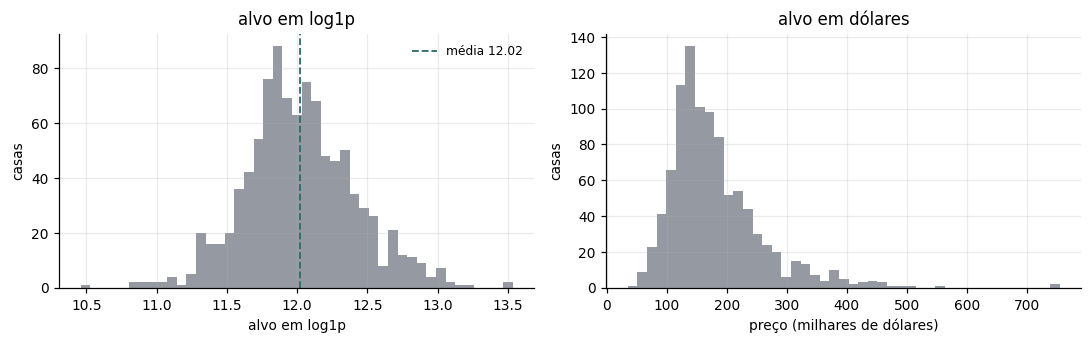

REFERÊNCIAS (escala log1p)

  chutar a média do treino   : MAE 0.3151
  chutar a mediana do treino : MAE 0.3156

  ReW publicada (Neurocomputing 416, Tabela 2): MAE 0.278

  variância do alvo no treino: 0.1537   desvio 0.3920
  0.278 em log1p equivale a 32.0% de erro relativo


In [176]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_train, bins=45, color=COR_REF, alpha=.9)
ax[0].axvline(y_train.mean(), color=COR_KAL, ls="--", lw=1.2, label=f"média {y_train.mean():.2f}")
ax[0].set(xlabel="alvo em log1p", ylabel="casas", title="alvo em log1p")
ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.expm1(y_train) / 1e3, bins=45, color=COR_REF, alpha=.9)
ax[1].set(xlabel="preço (milhares de dólares)", ylabel="casas", title="alvo em dólares")
plt.tight_layout(); plt.show()

print("REFERÊNCIAS (escala log1p)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  ReW publicada (Neurocomputing 416, Tabela 2): MAE {REF_ARTIGO:.3f}")
print(f"\n  variância do alvo no treino: {y_train.var():.4f}   desvio {y_train.std():.4f}")
print(f"  {REF_ARTIGO:.3f} em log1p equivale a {np.expm1(REF_ARTIGO):.1%} de erro relativo")

## 3.6 Binarização e mapping

Uma binarização e um `mapping` só, compartilhados por tudo que roda daqui para
baixo, para que a comparação entre as duas variantes seja controlada.

In [177]:
mins = X_train.min(axis=0).tolist()
maxs = X_train.max(axis=0).tolist()
DT = DynamicThermometer([THERM] * N_ATRIB, mins, maxs)

Xb_train = DT.transform(X_train)
Xb_test  = DT.transform(X_test)

RETINA  = Xb_train.shape[1]
MAPPING = sorteia_mapping(RETINA, ADDR, seed=SEED_MAPPING)
RET_OBJ = Retina(ADDR, MAPPING)
N_RAMS  = RET_OBJ.n_rams
N_ADDR  = RET_OBJ.n_addr

ADDR_TR = RET_OBJ.enderecos(Xb_train)
ADDR_TE = RET_OBJ.enderecos(Xb_test)

visitas = np.zeros((N_RAMS, N_ADDR), dtype=int)
for i in range(N_TREINO):
    visitas[np.arange(N_RAMS), ADDR_TR[i]] += 1
ocupadas = visitas[visitas > 0]

print(f"retina   : {RETINA} bits  ({N_ATRIB} atributos x {THERM})")
print(f"address  : {ADDR} bits  ->  {N_RAMS} RAM nodes x {N_ADDR} endereços")
print(f"mapping  : {len(MAPPING)} bits, seed {SEED_MAPPING}")
print(f"\ncélulas ocupadas: {len(ocupadas):,} de {N_RAMS*N_ADDR:,}")
print(f"visitas por célula ocupada: mín {ocupadas.min()}, mediana "
      f"{int(np.median(ocupadas))}, máx {ocupadas.max()}")

retina   : 8964 bits  (332 atributos x 27)
address  : 6 bits  ->  1494 RAM nodes x 64 endereços
mapping  : 8964 bits, seed 0

células ocupadas: 23,172 de 95,616
visitas por célula ocupada: mín 1, mediana 6, máx 952


---
# Seção 4 — R-KalWeNN

A Regression WiSARD guarda contador e soma. O R-KalWeNN troca os dois campos da
célula por estados de uma recursão de Kalman escalar:

| campo | o que é | converge para |
|---|---|---|
| $c_k$ | confiança do endereço, entre 0 e 1 | 1, de forma assintótica |
| $y_k$ | valor esperado de $y$ naquele endereço | a média local de $y$ |
| $p_{c,k}$, $p_{y,k}$ | covariância de cada um | regime dado por $q$ e $r$ |

Recursão, a cada observação:

$$
\bar{p} = p + q \qquad K = \frac{\bar{p}}{\bar{p} + r} \qquad
x \leftarrow x + K\,(z - x) \qquad p \leftarrow (1-K)\,\bar{p}
$$

Predição, com a média escolhida sobre os pares $(c_k, y_k)$ das células que o
exemplo endereça e que têm evidência:

$$
\hat{y} \;=\; \text{média}_{\,k}\big(c_k,\, y_k\big)
$$

## 4.1 A atualização de `c` e de `y`

**Estados iniciais.** $x_{0,c} = x_{0,y} = 0$, fixos. As covariâncias iniciais
são hiperparâmetros e nunca são zero: covariância nula não descreve uma
gaussiana, descreve um ponto exato no espaço de estados.

**A atualização de $c$.** Observação $z = 1$ quando o endereço é acessado;
célula não acessada não é tocada. É o `KalmanWiSARD` de classificação sem
alteração.

**A atualização de $y$.** $p_y$ cresce $q_y$ uma vez por acesso, e a correção
roda só no acesso, porque só aí existe um alvo para observar:

$$
p_y \leftarrow p_y + q_y, \qquad
K_y = \frac{p_y}{p_y + r_y}, \qquad
y \leftarrow y + K_y (y_i - y)
$$

Célula não acessada não é tocada por nenhuma das duas atualizações.

---
## 4.2 O que a confiança mede, e o que ela não mede

$c$ vai assintoticamente para 1, mas nenhuma célula chega lá: o que importa é o
valor depois das visitas que ela de fato recebe. Como o passo da atualização não
depende do valor observado, $c$ é função determinística do **número de visitas**.

**O que ela é.** Um contador que satura, com retorno decrescente por visita, e a
taxa de saturação é o hiperparâmetro.

**O que ela não é.** Uma medida de acerto. Duas células com o mesmo número de
visitas têm exatamente o mesmo $c$, mesmo que os $y$ de uma concordem e os da
outra não. Isso vale para $p$ também, porque a recursão da covariância não
contém $z$.

**Implementação.** Como $c$ só depende do contador, nada precisa tocar as
células não acessadas. A memória fica esparsa, com apenas as células visitadas,
e não há teto no `address_size`, o que é o que permite a varredura da seção 8.

In [178]:
class IndiceRK:
    """(ram, address) -> slot compacto, construído uma vez por (retina, treino).

    Só existem células que algum exemplo de treino visitou, o que vale para
    qualquer `address_size`: uma tabela densa de 2^address entradas por RAM node
    seria impossível já com 20 bits.
    """

    def __init__(self, retina, addr_fit):
        self.retina = retina
        self.slots_fit = np.empty_like(addr_fit)
        self._tab, off = [], 0
        for r_ in range(retina.n_rams):
            uniq, inv = np.unique(addr_fit[:, r_], return_inverse=True)
            self.slots_fit[:, r_] = inv + off
            self._tab.append((uniq, off))
            off += len(uniq)
        self.n_celulas = off

    def slots(self, addr):
        """(n, n_rams), com -1 onde o endereço não apareceu no treino."""
        out = np.full(addr.shape, -1, dtype=np.int64)
        for r_ in range(self.retina.n_rams):
            uniq, off = self._tab[r_]
            pos = np.clip(np.searchsorted(uniq, addr[:, r_]), 0, len(uniq) - 1)
            ok = uniq[pos] == addr[:, r_]
            out[ok, r_] = off + pos[ok]
        return out


print("IndiceRK definido")

IndiceRK definido


In [179]:
class RKalWeNN:
    """R-KalWeNN: Kalman nos dois campos da célula. Memória esparsa.

    ATUALIZAÇÃO DE c   observação z = 1 no acesso; célula não acessada não é
                       tocada. Como a recursão da covariância não contém z, o
                       estado c é função determinística do NÚMERO de visitas,
                       então ele é montado no fim, a partir dos contadores, sem
                       precisar de laço por exemplo.

    ATUALIZAÇÃO DE y   p_y cresce q_y uma vez por acesso, e a correção
                       roda só no acesso. Célula não acessada não é tocada
                       por nenhuma das duas.

    As duas coisas juntas deixam a memória esparsa: só existem células que algum
    exemplo de treino visitou. Não há teto no `address_size`.
    """

    def __init__(self, address_size, mapping, media=None,
                 q_c=1e-5, r_c=1.0, p0_c=1e-1,
                 q_y=1.5e-3, r_y=1.0, p0_y=144.0,
                 x0_c=0.0, x0_y=0.0, seed=0, indice=None):
        self.retina = Retina(address_size, mapping)
        self.media = media if media is not None else KSimpleMean()
        self.q_c, self.r_c, self.p0_c = q_c, r_c, p0_c
        self.q_y, self.r_y, self.p0_y = q_y, r_y, p0_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed
        self.indice = indice

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def tabela_c(self, nmax):
        """c(n) para n = 0..nmax. Não depende dos dados, só das covariâncias."""
        tab = np.zeros(nmax + 1)
        x, p = self.x0_c, self.p0_c
        for n in range(1, nmax + 1):
            pb = p + self.q_c
            k = pb / (pb + self.r_c)
            x += k * (1.0 - x)
            p = (1.0 - k) * pb
            tab[n] = x
        return tab

    def fit(self, Xb=None, y=None, addr=None):
        y = np.asarray(y, dtype=float)
        if self.indice is None:
            self.indice = IndiceRK(self.retina,
                                   self.retina.enderecos(Xb) if addr is None else addr)
        idx = self.indice
        ordem = np.random.default_rng(self.seed).permutation(len(y))

        Y    = np.full(idx.n_celulas, self.x0_y)
        PY   = np.full(idx.n_celulas, self.p0_y)
        cont = np.zeros(idx.n_celulas, dtype=np.int64)

        for i in ordem:
            s = idx.slots_fit[i]
            pp = PY[s] + self.q_y                      # predição, uma por visita
            ky = pp / (pp + self.r_y)                  # correção, só no acesso
            Y[s] += ky * (y[i] - Y[s])
            PY[s] = (1.0 - ky) * pp
            cont[s] += 1

        self.tab_c_ = self.tabela_c(int(cont.max()) if len(cont) else 0)
        self._C, self._Y, self._PY, self._cont = self.tab_c_[cont], Y, PY, cont
        self.n_celulas_ = idx.n_celulas
        return self

    def predict(self, Xb=None, media=None, slots=None):
        media = media or self.media
        if slots is None:
            slots = self.indice.slots(self.retina.enderecos(Xb))
        saida = np.empty(len(slots))
        for i in range(len(slots)):
            s = slots[i]
            ok = s >= 0
            pares = list(zip(self._C[s[ok]], self._Y[s[ok]]))
            saida[i] = media.calculate(pares) if pares else np.nan
        return saida

    def memoria_bytes(self):
        return self.n_celulas_ * 40    # chave + 4 floats


print("RKalWeNN definida (memória esparsa)")

RKalWeNN definida (memória esparsa)


---
# Seção 5 — Grid search

Busca conjunta: as **seis covariâncias e o tipo de média variam ao mesmo
tempo**. Os estados iniciais ficam fixos em zero.

Duas coisas que a busca sequencial anterior não fazia e que esta faz. Primeiro,
as seis covariâncias variam juntas, então o resultado é ótimo conjunto e não
ótimo por coordenada. Segundo, a média entra na busca: antes o MAE do grid era
sempre calculado com a aritmética ponderada, e o vencedor das covariâncias era
condicionado a essa escolha. Aqui o vencedor é o par (covariâncias, média), e
não existe agregação implícita.

A média age só no `predict`, então cada configuração de covariância é treinada
uma vez e as seis médias são lidas da mesma memória treinada. O resultado é
idêntico ao de um grid que retreinasse por média, e o custo é o das
covariâncias.

$3^6 = 729$ configurações por variante, três seeds cada, seis médias avaliadas
por ajuste.

## 5.0 A avaliação vetorizada

As médias em classe da seção 2.2 são a definição, e percorrem as 1494 RAM nodes
em laço Python. No grid isso é rodado $729 \times 3 \times 6$ vezes por variante
e domina o tempo.

Todas as seis se escrevem como reduções sobre matrizes $(n_{\text{teste}},
n_{\text{rams}})$, inclusive a mediana ponderada, que vira um `argsort` mais uma
soma acumulada. As duas formas foram conferidas uma contra a outra: diferença de
arredondamento, da ordem de $10^{-14}$, e mesmo padrão de NaN.

In [180]:
def coleta(modelo, slots):
    """(C, Y, V) de (n, n_rams) a partir dos slots do conjunto avaliado."""
    ok = slots >= 0
    s = np.where(ok, slots, 0)
    return modelo._C[s], modelo._Y[s], ok


def medias_vetorizadas(C, Y, V, nomes):
    """As seis médias ponderadas, em forma de redução sobre matrizes."""
    Cm = np.where(V, C, 0.0)
    sc = Cm.sum(1)
    ok = sc > 0
    V2 = V & (Y > 0)                       # harmônicas exigem y > 0
    Cm2 = np.where(V2, C, 0.0)
    sc2 = Cm2.sum(1)
    Yp = np.where(V2, Y, 1.0)              # só para dividir com segurança
    fin = lambda v, val: np.where(val, v, np.nan)
    out = {}

    if "K-SimpleMean" in nomes:
        out["K-SimpleMean"] = fin((Cm * Y).sum(1) / np.where(ok, sc, 1), ok)
    if "K-PowerMean(2)" in nomes:
        out["K-PowerMean(2)"] = fin(np.sqrt((Cm * Y ** 2).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-HarmonicMean" in nomes:
        s = (Cm2 / Yp).sum(1); o2 = s > 0
        out["K-HarmonicMean"] = fin(sc2 / np.where(o2, s, 1), o2)
    if "K-HarmonicPower(2)" in nomes:
        s = (Cm2 / Yp ** 2).sum(1); o2 = s > 0
        out["K-HarmonicPower(2)"] = fin(np.sqrt(sc2 / np.where(o2, s, 1)), o2)
    if "K-ExponentialMean" in nomes:
        out["K-ExponentialMean"] = fin(np.log((Cm * np.exp(Y)).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-Median" in nomes:
        o = np.argsort(Y, axis=1, kind="stable")
        Cs = np.take_along_axis(Cm, o, 1); Ys = np.take_along_axis(Y, o, 1)
        idx = (np.cumsum(Cs, axis=1) >= (sc / 2.0)[:, None]).argmax(1)
        out["K-Median"] = fin(Ys[np.arange(len(Y)), idx], ok)
    return out


IDX      = IndiceRK(RET_OBJ, ADDR_TR)
SLOTS_TE = IDX.slots(ADDR_TE)
print(f"IndiceRK do treino: {IDX.n_celulas:,} células ocupadas")
print("medias_vetorizadas definida")

IndiceRK do treino: 23,172 células ocupadas
medias_vetorizadas definida


In [181]:
def avalia(modelo, slots, y_ref, nomes):
    """Uma memória treinada, todas as médias. {nome: (MAE, RMSE, R2, nao_finito)}."""
    C, Y, V = coleta(modelo, slots)
    preds = medias_vetorizadas(C, Y, V, nomes)
    ss_tot = float(np.sum((y_ref - y_ref.mean()) ** 2))
    out = {}
    for nome, pr in preds.items():
        nao_fin = int((~np.isfinite(pr)).sum())
        if nao_fin:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        out[nome] = (mean_absolute_error(y_ref, pr),
                     float(np.sqrt(mean_squared_error(y_ref, pr))),
                     1.0 - float(np.sum((y_ref - pr) ** 2)) / ss_tot,
                     nao_fin)
    return out


def grid_kalman(indice, slots_te, y_tr, y_te, grids, seeds=SEEDS_GRID,
                nomes=None, mostrar=True, x0_c=X0_C, x0_y=X0_Y):
    """Grid conjunto das seis covariâncias, com a média variando junto.

    A média age só no predict, então cada configuração é treinada uma vez e
    todas as médias são lidas da mesma memória.
    """
    nomes = nomes or MEDIAS_NO_GRID
    combos = list(product(*grids))
    if mostrar:
        print(f"{len(combos)} covariâncias x {len(seeds)} seeds x {len(nomes)} médias")
    linhas, t0 = [], time.perf_counter()
    for n, (qc, rc, p0c, qy, ry, p0y) in enumerate(combos, 1):
        acum = {m: [] for m in nomes}
        for s in seeds:
            mod = RKalWeNN(indice.retina.address_size, indice.retina.mapping.ravel(),
                           q_c=qc, r_c=rc, p0_c=p0c, q_y=qy, r_y=ry, p0_y=p0y,
                           x0_c=x0_c, x0_y=x0_y, seed=s, indice=indice).fit(y=y_tr)
            for nome, v in avalia(mod, slots_te, y_te, nomes).items():
                acum[nome].append(v)
        for nome, vs in acum.items():
            a = np.array([v[:3] for v in vs], dtype=float)
            linhas.append(dict(media=nome, q_c=qc, r_c=rc, p0_c=p0c,
                               q_y=qy, r_y=ry, p0_y=p0y,
                               MAE=a[:, 0].mean(), MAE_dp=a[:, 0].std(),
                               RMSE=a[:, 1].mean(), R2=a[:, 2].mean(),
                               nao_finito=int(max(v[3] for v in vs))))
        if mostrar and n % 50 == 0:
            el = time.perf_counter() - t0
            print(f"  {n:>3}/{len(combos)}   {el/60:.1f} min, "
                  f"faltam ~{el/n*(len(combos)-n)/60:.1f} min")
    g = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
    if mostrar:
        print(f"concluído em {(time.perf_counter()-t0)/60:.1f} min")
    return g


print("avalia e grid_kalman definidos")

avalia e grid_kalman definidos


---
# Seção 8 — Varredura completa

Até aqui a codificação esteve congelada em thermometer 27 e address size 6, que
é a configuração escolhida para reproduzir o número publicado da ReW. Ela não é
necessariamente a melhor para o R-KalWeNN: o `c` muda quem conta quanto na
agregação, e o regime de colisão depende justamente do address size.

Com address 6 existem só 64 endereços por RAM node e 973 exemplos colidem muito:
a célula mais visitada recebe 543 dos 973. É o regime de colisão máxima, que é
onde a ponderação por contador mais atrapalha e onde o `c` mais tem o que
corrigir. Com address grande as células ficam esparsas e sobra menos o que
fazer.

Esta seção varre os quatro eixos ao mesmo tempo: **thermometer size, address
size, as seis covariâncias do Kalman e o tipo de média**.

## 8.1 Os eixos da busca

Todos os parâmetros da varredura estão na célula abaixo, separados dos da seção
1 pelo prefixo `SW_`, para poderem ser mexidos sem afetar as seções anteriores.

O `SW_Q_Y` ganhou o nível $1{,}5\cdot10^{-2}$, que faltava entre
$1{,}5\cdot10^{-3}$ e $1{,}5\cdot10^{-1}$. Sob o passo de predição por visita, é
nessa faixa que o ganho de regime cai entre 0,03 e 0,35, ou seja, onde a atualização de `y`
opera. Como o modo é amostrado com orçamento fixo, acrescentar nível não muda o
tempo, só o espaço de onde as configurações são sorteadas.

Os address sizes seguem o critério do `houseprice.py`: todos os divisores do
tamanho da retina, porque a retina precisa ser dividida em RAM nodes de tamanho
igual sem sobrar bit. O teto de 62 bits existe porque o endereço é montado em
inteiro de 64 bits e acima disso o índice estoura.

O custo de um ajuste é proporcional ao número de RAM nodes, que é
retina dividida por address size. Então **address size maior sai mais barato**,
e o eixo caro é o thermometer.

In [182]:
# ═══════════════════ EIXOS DA VARREDURA ══════════════════════════════════════
# Autossuficiente: os valores estão escritos aqui, não vêm da seção 1.
# Mexa só nesta célula e rode a 8.2 para ver o custo.

# ── codificação ──────────────────────────────────────────────────────────────
SW_THERM      = list(range(9, 27))   # bits de thermometer por atributo
SW_ADDR_MIN   =  4                    # menor address size aceito
SW_ADDR_MAX   =  5                   # 2^63 estoura o inteiro de 64 bits
SW_ADDR_LISTA = None                  # None = divisores da retina; ou uma lista

# ── c: observação z = 1 no acesso, estado entre 0 e 1 ───────────────────────
SW_Q_C  = [1e-6, 1e-5, 1e-4]
SW_R_C  = [1e-1, 1.0, 10.0]
SW_P0_C = [1e-2, 1e-1, 1.0]

# ── y: observação z = alvo do exemplo, estado ~ 12 em log1p ─────────────────
SW_Q_Y  = [1.5e-3, 1.5e-2, 1.5e-1, 1.5]
SW_R_Y  = [0.5, 1.0]
SW_P0_Y = [0.01, 0.5, 1.0]

# ── estados iniciais, médias, repetições ─────────────────────────────────────
SW_X0_C, SW_X0_Y = 0.0, 0.0
SW_MEDIAS = ["K-SimpleMean", "K-PowerMean(2)", "K-HarmonicMean",
             "K-HarmonicPower(2)", "K-ExponentialMean", "K-Median"]
SW_SEEDS  = (0, 1)

# ── orçamento ────────────────────────────────────────────────────────────────
#   "completo"  enumera o produto cartesiano inteiro
#   "amostrado" sorteia SW_ORCAMENTO configurações do produto, sem repetir
SW_MODO         = "amostrado"
SW_ORCAMENTO    = 1500
SW_SEED_AMOSTRA = 0
SW_ARQUIVO      = "varredura_rkalwenn.csv"


# ═══════════════════ o que isso gera ═════════════════════════════════════════
def divisores(v, lo=SW_ADDR_MIN, hi=SW_ADDR_MAX):
    """Divisores de v em [lo, hi], mais v se couber. Como o allDividers do
    houseprice.py, com teto para o índice de 64 bits não estourar."""
    d = [i for i in range(lo, int(v / 2) + 1) if v % i == 0 and i <= hi]
    return d + ([v] if lo <= v <= hi else [])


PARES = [(t, a) for t in SW_THERM
         for a in (SW_ADDR_LISTA if SW_ADDR_LISTA is not None
                   else divisores(t * N_ATRIB))]
N_KAL = (len(SW_Q_C) * len(SW_R_C) * len(SW_P0_C) *
         len(SW_Q_Y) * len(SW_R_Y) * len(SW_P0_Y))

print("EIXOS EM USO\n")
for nome, val in [("thermometer", SW_THERM), ("q_c", SW_Q_C), ("r_c", SW_R_C),
                  ("p0_c", SW_P0_C), ("q_y", SW_Q_Y), ("r_y", SW_R_Y),
                  ("p0_y", SW_P0_Y), ("médias", SW_MEDIAS), ("seeds", list(SW_SEEDS))]:
    s = str(val)
    print(f"  {nome:<12} {len(val):>2} níveis   {s if len(s) < 62 else s[:59] + '...'}")
_addr_txt = (f"divisores da retina em [{SW_ADDR_MIN}, {SW_ADDR_MAX}]"
             if SW_ADDR_LISTA is None else str(SW_ADDR_LISTA))
print(f"  {'address':<12}            {_addr_txt}")
print(f"  {'x0_c, x0_y':<12}            {SW_X0_C}, {SW_X0_Y}")

print(f"\nTAMANHO\n")
print(f"  pares (thermometer, address) : {len(PARES)}")
print(f"  covariâncias                 : {N_KAL}")
print(f"  produto completo             : {len(PARES)*N_KAL:,} configurações"
      f" = {len(PARES)*N_KAL*len(SW_SEEDS):,} ajustes")
print(f"  modo                         : {SW_MODO}"
      + (f", orçamento {SW_ORCAMENTO:,}" if SW_MODO == "amostrado" else ""))
print(f"  médias                       : de graça, lidas do mesmo ajuste")

EIXOS EM USO

  thermometer  18 níveis   [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23,...
  q_c           3 níveis   [1e-06, 1e-05, 0.0001]
  r_c           3 níveis   [0.1, 1.0, 10.0]
  p0_c          3 níveis   [0.01, 0.1, 1.0]
  q_y           4 níveis   [0.0015, 0.015, 0.15, 1.5]
  r_y           2 níveis   [0.5, 1.0]
  p0_y          3 níveis   [0.01, 0.5, 1.0]
  médias        6 níveis   ['K-SimpleMean', 'K-PowerMean(2)', 'K-HarmonicMean', 'K-Har...
  seeds         2 níveis   [0, 1]
  address                 divisores da retina em [4, 5]
  x0_c, x0_y              0.0, 0.0

TAMANHO

  pares (thermometer, address) : 22
  covariâncias                 : 648
  produto completo             : 14,256 configurações = 28,512 ajustes
  modo                         : amostrado, orçamento 1,500
  médias                       : de graça, lidas do mesmo ajuste


## 8.2 Estimativa de custo, antes de rodar

Mede um ajuste em três pares (thermometer, address) de tamanhos diferentes e
extrapola pelo número de RAM nodes, que é o que domina. Rode esta célula antes
da busca para saber no que está se metendo.

In [183]:
def custo_por_ram_node():
    """Segundos por RAM node por ajuste, medido em três tamanhos."""
    amostras = []
    for t, a in [PARES[0], PARES[len(PARES)//2], PARES[-1]]:
        dt = DynamicThermometer([t]*N_ATRIB, mins, maxs)
        Xb = dt.transform(X_train)
        ret = Retina(a, sorteia_mapping(Xb.shape[1], a, seed=SEED_MAPPING))
        idx = IndiceRK(ret, ret.enderecos(Xb))
        t0 = time.perf_counter()
        RKalWeNN(a, ret.mapping.ravel(), indice=idx, seed=0, x0_c=SW_X0_C, x0_y=SW_X0_Y).fit(y=y_train)
        amostras.append(((time.perf_counter()-t0) / ret.n_rams, ret.n_rams, t, a))
    return float(np.median([s[0] for s in amostras])), amostras


seg_por_ram, amostras = custo_por_ram_node()
print("medições:")
for s, nr, t, a in amostras:
    print(f"  therm {t:>2}, address {a:>4} -> {nr:>5} RAM nodes, "
          f"{s*nr:.3f} s por ajuste")

rams_total = sum(t * N_ATRIB // a for t, a in PARES)
n_cfg = len(PARES) * N_KAL if SW_MODO == "completo" else min(SW_ORCAMENTO, len(PARES)*N_KAL)
frac = n_cfg / (len(PARES) * N_KAL)
seg = rams_total * N_KAL * frac * len(SW_SEEDS) * seg_por_ram

fim = time.strftime("%d/%m %H:%M", time.localtime(time.time() + seg))
print(f"\nestimativa para {n_cfg:,} configurações x {len(SW_SEEDS)} seeds:")
print(f"  {seg/60:,.0f} min  ({seg/3600:,.1f} h)")
print(f"  começando agora, termina por volta de {fim}")

seg_completo = rams_total * N_KAL * len(SW_SEEDS) * seg_por_ram
print(f"\nproduto completo ({len(PARES)*N_KAL:,} configurações): "
      f"{seg_completo/3600:,.0f} h")
print("\nAjuste SW_ORCAMENTO, SW_THERM ou os níveis das covariâncias e rode de novo.")

medições:
  therm  9, address    4 ->   747 RAM nodes, 0.112 s por ajuste
  therm 18, address    4 ->  1494 RAM nodes, 0.157 s por ajuste
  therm 26, address    4 ->  2158 RAM nodes, 0.336 s por ajuste

estimativa para 1,500 configurações x 2 seeds:
  10 min  (0.2 h)
  começando agora, termina por volta de 27/08 17:59

produto completo (14,256 configurações): 2 h

Ajuste SW_ORCAMENTO, SW_THERM ou os níveis das covariâncias e rode de novo.


## 8.3 A busca

Grava um CSV parcial a cada par (thermometer, address), então dá para
interromper e retomar a leitura do que já rodou.

A binarização é refeita uma vez por thermometer e o índice uma vez por par
(thermometer, address); as covariâncias e as médias reaproveitam os dois.

In [184]:
combos_kal = list(product(SW_Q_C, SW_R_C, SW_P0_C, SW_Q_Y, SW_R_Y, SW_P0_Y))
rng_am = np.random.default_rng(SW_SEED_AMOSTRA)

if SW_MODO == "amostrado":
    todos = [(p, k) for p in range(len(PARES)) for k in range(len(combos_kal))]
    escolha = rng_am.choice(len(todos), size=min(SW_ORCAMENTO, len(todos)), replace=False)
    plano = {}
    for e in escolha:
        ip, ik = todos[e]
        plano.setdefault(ip, []).append(ik)
else:
    plano = {ip: list(range(len(combos_kal))) for ip in range(len(PARES))}

n_total = sum(len(v) for v in plano.values())

# O custo de um ajuste é proporcional ao número de RAM nodes, que varia de
# dezenas a milhares entre os pares. Extrapolar por contagem de configurações
# daria previsão errada, então o progresso é medido em RAM nodes ajustados.
def rams_do_par(ip):
    t, a = PARES[ip]
    return t * N_ATRIB // a

trabalho_total = sum(rams_do_par(ip) * len(v) * len(SW_SEEDS)
                     for ip, v in plano.items())

print(f"{n_total:,} configurações em {len(plano)} pares (thermometer, address)")
print(f"trabalho total: {trabalho_total:,} ajustes de RAM node\n")

with open(SW_ARQUIVO, "w") as f:
    f.write("therm,address,n_rams,media,q_c,r_c,p0_c,q_y,r_y,p0_y,"
            "MAE,MAE_dp,RMSE,R2,nao_finito\n")

linhas, feitas, trabalho_feito, t0 = [], 0, 0, time.perf_counter()
therm_atual, Xb_tr_s, Xb_te_s = None, None, None

for ip in sorted(plano):
    t, a = PARES[ip]
    if t != therm_atual:                                   # binariza uma vez por therm
        dt = DynamicThermometer([t] * N_ATRIB, mins, maxs)
        Xb_tr_s, Xb_te_s = dt.transform(X_train), dt.transform(X_test)
        therm_atual = t
    ret = Retina(a, sorteia_mapping(Xb_tr_s.shape[1], a, seed=SEED_MAPPING))
    idx = IndiceRK(ret, ret.enderecos(Xb_tr_s))
    sl_te = idx.slots(ret.enderecos(Xb_te_s))

    for ik in plano[ip]:
        qc, rc, p0c, qy, ry, p0y = combos_kal[ik]
        g = grid_kalman(idx, sl_te, y_train, y_test,
                        ([qc], [rc], [p0c], [qy], [ry], [p0y]),
                        seeds=SW_SEEDS, nomes=SW_MEDIAS, mostrar=False,
                        x0_c=SW_X0_C, x0_y=SW_X0_Y)
        g.insert(0, "n_rams", ret.n_rams); g.insert(0, "address", a); g.insert(0, "therm", t)
        linhas.append(g)
        with open(SW_ARQUIVO, "a") as f:
            for _, r in g.iterrows():
                f.write(f"{t},{a},{ret.n_rams},{r.media},{r.q_c},{r.r_c},{r.p0_c},"
                        f"{r.q_y},{r.r_y},{r.p0_y},{r.MAE:.6f},{r.MAE_dp:.6f},"
                        f"{r.RMSE:.6f},{r.R2:.6f},{int(r.nao_finito)}\n")
        feitas += 1
        trabalho_feito += ret.n_rams * len(SW_SEEDS)

    el = time.perf_counter() - t0
    restante = el * (trabalho_total - trabalho_feito) / max(trabalho_feito, 1)
    fim = time.strftime("%H:%M", time.localtime(time.time() + restante))
    print(f"  therm {t:>2} address {a:>4} ({ret.n_rams:>5} rams)  "
          f"{feitas:>5}/{n_total} cfg  {100*trabalho_feito/trabalho_total:>5.1f}% "
          f"do trabalho  |  {el/60:>5.1f} min corridos, "
          f"faltam ~{restante/60:>5.0f} min, término ~{fim}")

varredura = pd.concat(linhas, ignore_index=True).sort_values("MAE").reset_index(drop=True)
_tot = time.perf_counter() - t0
print(f"\nconcluído em {_tot/60:.1f} min ({_tot/3600:.2f} h), "
      f"{len(varredura):,} linhas gravadas em {SW_ARQUIVO}")
print(f"média de {_tot/max(feitas,1):.2f} s por configuração "
      f"({1e3*_tot/max(trabalho_feito,1):.3f} ms por ajuste de RAM node)")

1,500 configurações em 22 pares (thermometer, address)
trabalho total: 4,250,264 ajustes de RAM node

  therm  9 address    4 (  747 rams)     61/1500 cfg    2.1% do trabalho  |    0.4 min corridos, faltam ~   17 min, término ~18:05
  therm 10 address    4 (  830 rams)    129/1500 cfg    4.8% do trabalho  |    0.8 min corridos, faltam ~   17 min, término ~18:06
  therm 10 address    5 (  664 rams)    190/1500 cfg    6.7% do trabalho  |    1.2 min corridos, faltam ~   17 min, término ~18:06
  therm 11 address    4 (  913 rams)    259/1500 cfg    9.7% do trabalho  |    1.7 min corridos, faltam ~   16 min, término ~18:06
  therm 12 address    4 (  996 rams)    321/1500 cfg   12.6% do trabalho  |    2.1 min corridos, faltam ~   15 min, término ~18:05
  therm 13 address    4 ( 1079 rams)    388/1500 cfg   16.0% do trabalho  |    2.6 min corridos, faltam ~   13 min, término ~18:04
  therm 14 address    4 ( 1162 rams)    451/1500 cfg   19.4% do trabalho  |    3.0 min corridos, faltam ~   13 m

## 8.4 A ReW na configuração vencedora da varredura

Roda a Regression WiSARD no thermometer e no address que deram o melhor MAE do
R-KalWeNN, com o mesmo `mapping` e o mesmo split. Cada modelo com a família de
média dele: a ReW com as médias sem prefixo da seção 2.2, o R-KalWeNN com as
`K-`.

O `mapping` é o mesmo da varredura, sorteado com `SEED_MAPPING`, então a ReW é
determinística aqui e não tem desvio entre execuções.

In [185]:
if "varredura" not in globals():
    varredura = pd.read_csv(SW_ARQUIVO).sort_values("MAE").reset_index(drop=True)

V = varredura.loc[0]
T_V, A_V = int(V.therm), int(V.address)
print(f"configuração vencedora do R-KalWeNN: thermometer {T_V}, address {A_V}, "
      f"{int(V.n_rams)} RAM nodes")
print(f"  {V.media}, MAE {V.MAE:.4f} ± {V.MAE_dp:.4f}, R2 {V.R2:.4f}\n")

dt_v = DynamicThermometer([T_V] * N_ATRIB, mins, maxs)
Xb_tr_v, Xb_te_v = dt_v.transform(X_train), dt_v.transform(X_test)
map_v = sorteia_mapping(Xb_tr_v.shape[1], A_V, seed=SEED_MAPPING)
ret_v = Retina(A_V, map_v)

ss_tot = float(np.sum((y_test - y_test.mean()) ** 2))
linhas, t0 = [], time.perf_counter()
for nome, m in medias_rew().items():
    pr = RegressionWiSARD(A_V, m, map_v).fit(Xb_tr_v, y_train).predict(Xb_te_v)
    nf = int((~np.isfinite(pr)).sum())
    if nf:
        bons = pr[np.isfinite(pr)]
        pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
    linhas.append({"modelo": "ReW", "media": nome,
                   "MAE": mean_absolute_error(y_test, pr),
                   "RMSE": float(np.sqrt(mean_squared_error(y_test, pr))),
                   "R2": 1.0 - float(np.sum((y_test - pr) ** 2)) / ss_tot,
                   "nao_finito": nf})
    print(f"  ReW {nome:<18} ok  ({time.perf_counter()-t0:.0f} s)")

rew_venc = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
print(f"\nReW em thermometer {T_V}, address {A_V}, {ret_v.n_rams} RAM nodes\n")
print(rew_venc.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

kal_no_ponto = varredura[(varredura.therm == T_V) & (varredura.address == A_V)]
print(f"\n\nR-KalWeNN no mesmo ponto, melhor por média\n")
print(kal_no_ponto.groupby("media").MAE.min().sort_values()
      .to_string(float_format=lambda v: f"{v:.4f}"))

print(f"\n\nMELHOR DE CADA UM, no mesmo thermometer {T_V} e address {A_V}\n")
b_rew, b_kal = rew_venc.MAE.min(), kal_no_ponto.MAE.min()
print(f"  ReW ({rew_venc.loc[0,'media']}):{'':<8}{b_rew:.4f}")
print(f"  R-KalWeNN ({kal_no_ponto.loc[kal_no_ponto.MAE.idxmin(), 'media']}):"
      f"{'':<3}{b_kal:.4f}")
print(f"  diferença: {(b_kal/b_rew - 1)*100:+.1f}%")
print(f"  ReW publicada (Neurocomputing 416): {REF_ARTIGO:.3f}")

configuração vencedora do R-KalWeNN: thermometer 20, address 5, 1328 RAM nodes
  K-HarmonicPower(2), MAE 0.2531 ± 0.0056, R2 0.3035

  ReW SimpleMean         ok  (4 s)
  ReW PowerMean(2)       ok  (7 s)
  ReW HarmonicMean       ok  (10 s)
  ReW HarmonicPower(2)   ok  (13 s)
  ReW ExponentialMean    ok  (17 s)
  ReW Median             ok  (22 s)

ReW em thermometer 20, address 5, 1328 RAM nodes

modelo            media    MAE   RMSE     R2  nao_finito
   ReW HarmonicPower(2) 0.2563 0.3410 0.2956           0
   ReW  ExponentialMean 0.2563 0.3394 0.3022           0
   ReW     HarmonicMean 0.2563 0.3409 0.2958           0
   ReW     PowerMean(2) 0.2564 0.3407 0.2966           0
   ReW           Median 0.2851 0.3728 0.1578           0
   ReW       SimpleMean 0.2904 0.3807 0.1221           0


R-KalWeNN no mesmo ponto, melhor por média

media
K-HarmonicPower(2)   0.2531
K-HarmonicMean       0.2535
K-SimpleMean         0.2546
K-PowerMean(2)       0.2551
K-ExponentialMean    0.2586
K-Median   

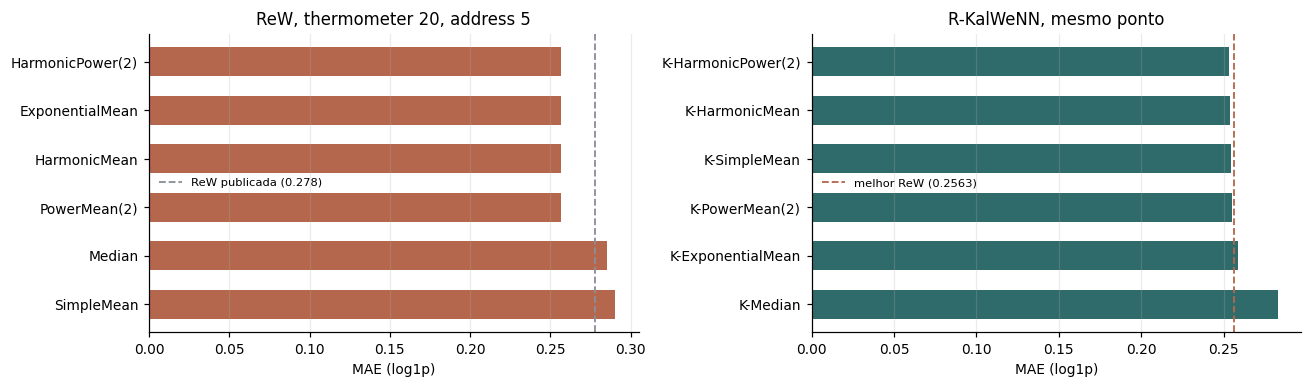

In [189]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))

o = rew_venc.sort_values("MAE", ascending=False)
ax[0].barh(np.arange(len(o)), o.MAE, color=COR_REW, height=.6)
ax[0].axvline(REF_ARTIGO, color=COR_REF, ls="--", lw=1.2, label=f"ReW publicada ({REF_ARTIGO})")
ax[0].set(yticks=np.arange(len(o)), yticklabels=o.media, xlabel="MAE (log1p)",
          title=f"ReW, thermometer {T_V}, address {A_V}")
ax[0].grid(axis="y", visible=False); ax[0].legend(frameon=False, fontsize=7.5)

k = kal_no_ponto.groupby("media").MAE.min().sort_values(ascending=False)
ax[1].barh(np.arange(len(k)), k.values, color=COR_KAL, height=.6)
ax[1].axvline(b_rew, color=COR_REW, ls="--", lw=1.2, label=f"melhor ReW ({b_rew:.4f})")
ax[1].set(yticks=np.arange(len(k)), yticklabels=k.index, xlabel="MAE (log1p)",
          title=f"R-KalWeNN, mesmo ponto")
ax[1].grid(axis="y", visible=False); ax[1].legend(frameon=False, fontsize=7.5)
plt.tight_layout(); plt.show()

## 8.5 Quantos endereços cada RAM node acessa, e quantas vezes

Na configuração vencedora da varredura. Cada RAM node tem `2^address` endereços
possíveis, mas só existem os que algum exemplo de treino visitou.

Duas contagens diferentes, que não devem ser confundidas. **Endereços ocupados
por RAM node** é quantos endereços distintos aquele neurônio chegou a usar.
**Visitas por endereço** é quantos exemplos de treino caíram em cada um deles.
A soma das visitas de um RAM node é sempre o número de exemplos de treino,
porque todo exemplo endereça todos os RAM nodes.

In [190]:
# thermometer e address desta análise: por padrão os vencedores da varredura
if "varredura" not in globals():
    varredura = pd.read_csv(SW_ARQUIVO).sort_values("MAE").reset_index(drop=True)
T_A = int(varredura.loc[0, "therm"])
A_A = int(varredura.loc[0, "address"])
# ─────────────────────────────────────────────────────────────────────────────

dt_a = DynamicThermometer([T_A] * N_ATRIB, mins, maxs)
Xb_a = dt_a.transform(X_train)
ret_a = Retina(A_A, sorteia_mapping(Xb_a.shape[1], A_A, seed=SEED_MAPPING))
addr_a = ret_a.enderecos(Xb_a)

# visitas[r] = {endereço: quantas vezes}
ocupados, visitas = [], []
for r_ in range(ret_a.n_rams):
    _, cont_r = np.unique(addr_a[:, r_], return_counts=True)
    ocupados.append(len(cont_r))
    visitas.append(cont_r)
ocupados = np.array(ocupados)
todas = np.concatenate(visitas)
min_por_ram = np.array([v.min() for v in visitas])
max_por_ram = np.array([v.max() for v in visitas])
med_por_ram = np.array([np.median(v) for v in visitas])

print(f"thermometer {T_A}, address {A_A}  ->  {ret_a.n_rams} RAM nodes, "
      f"{ret_a.n_addr:,} endereços possíveis por RAM node")
print(f"{N_TREINO} exemplos de treino\n")

print("ENDEREÇOS OCUPADOS POR RAM NODE\n")
print(f"  mínimo {ocupados.min()}   mediana {int(np.median(ocupados))}   "
      f"máximo {ocupados.max()}   média {ocupados.mean():.1f}")
print(f"  de {ret_a.n_addr:,} possíveis, ou seja "
      f"{100*ocupados.mean()/ret_a.n_addr:.2f}% em média")
print(f"  total de células ocupadas: {ocupados.sum():,}")

print("\nVISITAS POR ENDEREÇO OCUPADO\n")
print(f"  mínimo {todas.min()}   mediana {int(np.median(todas))}   "
      f"máximo {todas.max()}   média {todas.mean():.1f}")
print(f"  endereços com 1 visita só: {100*(todas==1).mean():.1f}%")
print(f"  endereços com 2 ou mais  : {100*(todas>=2).mean():.1f}%")

print("\nO ENDEREÇO MENOS E MAIS VISITADO DE CADA RAM NODE\n")
print(f"  menos visitado : mínimo {min_por_ram.min()}, "
      f"mediana {int(np.median(min_por_ram))}, máximo {min_por_ram.max()}")
print(f"  mais visitado  : mínimo {max_por_ram.min()}, "
      f"mediana {int(np.median(max_por_ram))}, máximo {max_por_ram.max()}")
print(f"  mediana do RAM node : mínimo {med_por_ram.min():.1f}, "
      f"mediana {np.median(med_por_ram):.1f}, máximo {med_por_ram.max():.1f}")
print(f"\n  o RAM node mais concentrado tem um endereço com {max_por_ram.max()} "
      f"dos {N_TREINO} exemplos ({100*max_por_ram.max()/N_TREINO:.0f}%)")
print(f"  o RAM node mais espalhado tem no máximo {max_por_ram.min()} "
      f"exemplos num mesmo endereço")

print("\nOS 5 RAM NODES MAIS CONCENTRADOS E OS 5 MAIS ESPALHADOS\n")
tab = pd.DataFrame({"ram": np.arange(ret_a.n_rams), "enderecos_ocupados": ocupados,
                    "visitas_min": min_por_ram, "visitas_max": max_por_ram,
                    "visitas_mediana": med_por_ram})
print(tab.nlargest(5, "visitas_max").to_string(index=False))
print()
print(tab.nsmallest(5, "visitas_max").to_string(index=False))

thermometer 20, address 5  ->  1328 RAM nodes, 32 endereços possíveis por RAM node
973 exemplos de treino

ENDEREÇOS OCUPADOS POR RAM NODE

  mínimo 4   mediana 11   máximo 27   média 11.5
  de 32 possíveis, ou seja 35.89% em média
  total de células ocupadas: 15,250

VISITAS POR ENDEREÇO OCUPADO

  mínimo 1   mediana 9   máximo 962   média 84.7
  endereços com 1 visita só: 19.9%
  endereços com 2 ou mais  : 80.1%

O ENDEREÇO MENOS E MAIS VISITADO DE CADA RAM NODE

  menos visitado : mínimo 1, mediana 1, máximo 9
  mais visitado  : mínimo 125, mediana 634, máximo 962
  mediana do RAM node : mínimo 1.0, mediana 9.0, máximo 89.0

  o RAM node mais concentrado tem um endereço com 962 dos 973 exemplos (99%)
  o RAM node mais espalhado tem no máximo 125 exemplos num mesmo endereço

OS 5 RAM NODES MAIS CONCENTRADOS E OS 5 MAIS ESPALHADOS

 ram  enderecos_ocupados  visitas_min  visitas_max  visitas_mediana
 222                   5            1          962              3.0
 799               

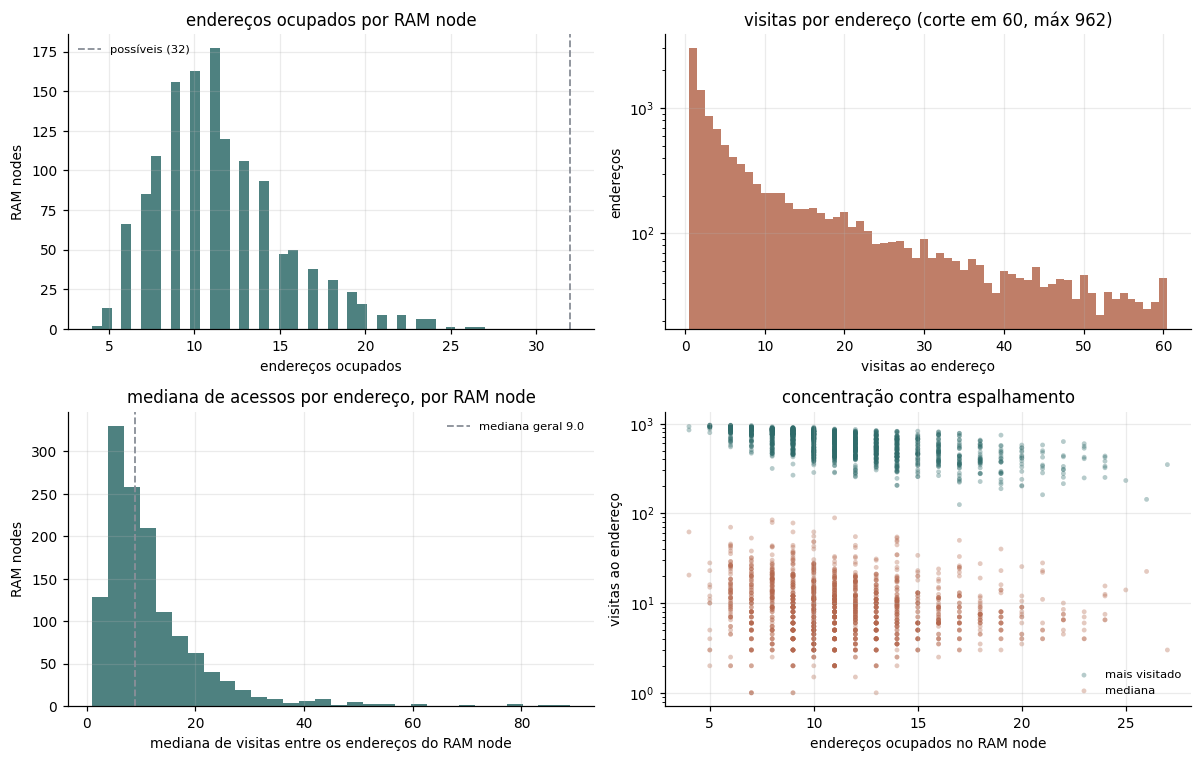

In [191]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))

ax[0, 0].hist(ocupados, bins=40, color=COR_KAL, alpha=.85)
ax[0, 0].axvline(ret_a.n_addr, color=COR_REF, ls="--", lw=1.2,
                 label=f"possíveis ({ret_a.n_addr:,})")
ax[0, 0].set(xlabel="endereços ocupados", ylabel="RAM nodes",
             title="endereços ocupados por RAM node")
ax[0, 0].legend(frameon=False, fontsize=7.5)

ax[0, 1].hist(todas, bins=np.arange(1, min(todas.max(), 60) + 2) - .5,
              color=COR_REW, alpha=.85)
ax[0, 1].set(xlabel="visitas ao endereço", ylabel="endereços", yscale="log",
             title=f"visitas por endereço (corte em 60, máx {todas.max()})")

ax[1, 0].hist(med_por_ram, bins=30, color=COR_KAL, alpha=.85)
ax[1, 0].axvline(np.median(med_por_ram), color=COR_REF, ls="--", lw=1.2,
                 label=f"mediana geral {np.median(med_por_ram):.1f}")
ax[1, 0].set(xlabel="mediana de visitas entre os endereços do RAM node",
             ylabel="RAM nodes", title="mediana de acessos por endereço, por RAM node")
ax[1, 0].legend(frameon=False, fontsize=7.5)

ax[1, 1].scatter(ocupados, max_por_ram, s=10, alpha=.35, color=COR_KAL,
                 edgecolor="none", label="mais visitado")
ax[1, 1].scatter(ocupados, med_por_ram, s=10, alpha=.35, color=COR_REW,
                 edgecolor="none", label="mediana")
ax[1, 1].set(xlabel="endereços ocupados no RAM node", ylabel="visitas ao endereço",
             yscale="log", title="concentração contra espalhamento")
ax[1, 1].legend(frameon=False, fontsize=7.5)
plt.tight_layout(); plt.show()

## 8.6 Resultado da varredura

O número de RAM nodes entra no lugar do address size, porque a grade
thermometer × address só tem 16% das células preenchidas e não dá para comparar
address entre thermometers diferentes.

 therm  address  n_rams              media    q_c  r_c  p0_c    q_y  r_y  p0_y    MAE   MAE_dp     R2
    20        5    1328 K-HarmonicPower(2) 0.0001  0.1   0.1 0.0015  0.5     1 0.2531 0.005576 0.3035
    20        5    1328     K-HarmonicMean 0.0001  0.1   0.1 0.0015  0.5     1 0.2535 0.005341  0.302
    15        5     996 K-HarmonicPower(2)  1e-06    1     1 0.0015  0.5     1  0.254 0.005327 0.2995
    15        5     996     K-HarmonicMean  1e-05  0.1     1 0.0015  0.5     1 0.2542 0.005531 0.2976
    15        5     996 K-HarmonicPower(2)  1e-05  0.1     1 0.0015  0.5     1 0.2543 0.005829 0.2964
    15        5     996     K-HarmonicMean  1e-06    1     1 0.0015  0.5     1 0.2543 0.005078 0.2988
    25        5    1660 K-HarmonicPower(2)  1e-05    1     1 0.0015  0.5     1 0.2544 0.005435 0.2974
    15        5     996       K-SimpleMean  1e-05  0.1     1 0.0015  0.5     1 0.2545 0.004999 0.2977
    20        5    1328       K-SimpleMean 0.0001  0.1   0.1 0.0015  0.5     1 0.2

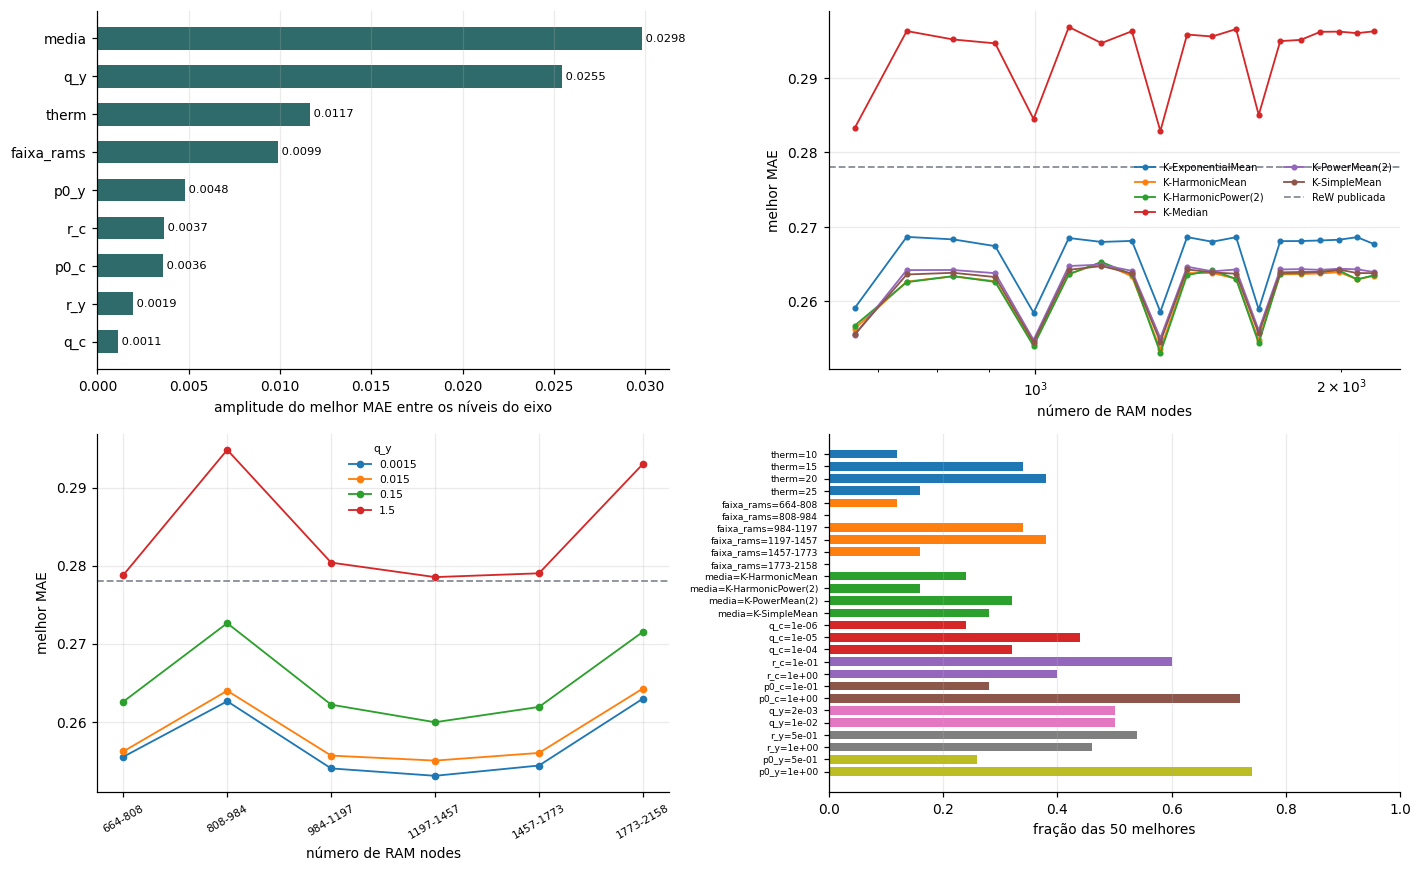

In [192]:
if "varredura" not in globals():
    varredura = pd.read_csv(SW_ARQUIVO).sort_values("MAE").reset_index(drop=True)

v = varredura.copy()

bins = np.unique(np.geomspace(v.n_rams.min(), v.n_rams.max(), 7).round().astype(int))
v["faixa_rams"] = pd.cut(v.n_rams, bins=bins, include_lowest=True,
                         labels=[f"{bins[i]}-{bins[i+1]}" for i in range(len(bins)-1)])

EIXOS = ["therm", "faixa_rams", "media",
         "q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y"]
TOPK = min(50, len(v))
top = v.nsmallest(TOPK, "MAE")

cols = ["therm", "address", "n_rams", "media", "q_c", "r_c", "p0_c",
        "q_y", "r_y", "p0_y", "MAE", "MAE_dp", "R2"]
print(v.head(10)[cols].to_string(index=False, float_format=lambda x: f"{x:.4g}"))
b = v.loc[0]
print(f"\nmelhor: therm {int(b.therm)}, address {int(b.address)}, "
      f"{int(b.n_rams)} rams, {b.media}, MAE {b.MAE:.4f} ± {b.MAE_dp:.4f}, R2 {b.R2:.4f}")
print(f"ReW publicada: MAE {REF_ARTIGO:.3f}   |   {len(v):,} linhas na varredura")

fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# 1 ── amplitude do melhor MAE por eixo
amp = {}
for e in EIXOS:
    m = v.groupby(e, observed=True).MAE.min()
    amp[e] = float(m.max() - m.min()) if len(m) > 1 else 0.0
amp = pd.Series(amp).sort_values()
ax[0, 0].barh(np.arange(len(amp)), amp.values, color=COR_KAL, height=.6)
ax[0, 0].set(yticks=np.arange(len(amp)), yticklabels=amp.index,
             xlabel="amplitude do melhor MAE entre os níveis do eixo")
ax[0, 0].grid(axis="y", visible=False)
for i, val in enumerate(amp.values):
    ax[0, 0].text(val, i, f" {val:.4f}", va="center", fontsize=7.5)

# 2 ── melhor MAE por número de RAM nodes, uma linha por média
piv = v.groupby(["n_rams", "media"], observed=True).MAE.min().unstack()
for m in piv.columns:
    s = piv[m].dropna()
    ax[0, 1].plot(s.index, s.values, "o-", lw=1.2, ms=3, label=m)
ax[0, 1].axhline(REF_ARTIGO, color=COR_REF, ls="--", lw=1.2, label="ReW publicada")
ax[0, 1].set(xscale="log", xlabel="número de RAM nodes", ylabel="melhor MAE")
ax[0, 1].legend(frameon=False, fontsize=6.5, ncol=2)

# 3 ── melhor MAE por número de RAM nodes, uma linha por q_c/r_c
piv2 = v.groupby(["faixa_rams", "q_y"], observed=True).MAE.min().unstack()
for r in piv2.columns:
    s = piv2[r].dropna()
    ax[1, 0].plot(range(len(piv2.index)), piv2[r].values, "o-", lw=1.2, ms=4,
                  label=f"{r:g}")
ax[1, 0].axhline(REF_ARTIGO, color=COR_REF, ls="--", lw=1.2)
ax[1, 0].set(xticks=range(len(piv2.index)), xticklabels=piv2.index,
             xlabel="número de RAM nodes", ylabel="melhor MAE")
ax[1, 0].tick_params(axis="x", labelrotation=30, labelsize=7)
ax[1, 0].legend(frameon=False, fontsize=7, title="q_y", title_fontsize=7)

# 4 ── composição das TOPK melhores
comp, rot = [], []
for e in EIXOS:
    f = top[e].value_counts(normalize=True).sort_index()
    for niv, frac in f.items():
        comp.append(frac)
        rot.append(f"{e}={niv:.0e}" if isinstance(niv, float) else f"{e}={niv}")
y = np.arange(len(comp))
cores = []
for r in rot:
    e = r.split("=")[0]
    cores.append(plt.cm.tab10(EIXOS.index(e) % 10))
ax[1, 1].barh(y, comp, color=cores, height=.7)
ax[1, 1].set(yticks=y, yticklabels=rot, xlabel=f"fração das {TOPK} melhores", xlim=(0, 1))
ax[1, 1].tick_params(axis="y", labelsize=6)
ax[1, 1].grid(axis="y", visible=False)
ax[1, 1].invert_yaxis()

plt.tight_layout(); plt.show()

---
# Seção 9 — A curva de `c`

`c` entra na predição multiplicando, então é ele que decide o quanto cada RAM
node conta na agregação. A ReW crua entra como referência: lá quem multiplica é
o contador puro, e uma célula de 543 visitas conta 543 vezes mais que uma de 1
visita.

Usa os níveis de `GRID_Q_C` e `GRID_R_C` definidos na célula da seção 5.

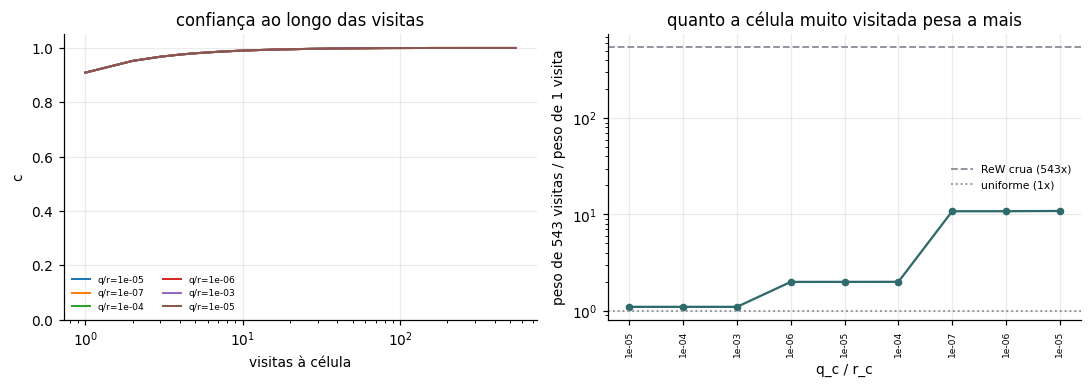

      q_c     r_c      n=1      n=6     n=20     n=64    n=271    n=543
-----------------------------------------------------------------------
    1e-06     0.1   0.9091   0.9836   0.9950   0.9985   0.9997   0.9999
    1e-06       1   0.5000   0.8571   0.9524   0.9846   0.9964   0.9982
    1e-06      10   0.0909   0.3750   0.6667   0.8649   0.9645   0.9820
    1e-05     0.1   0.9091   0.9836   0.9951   0.9985   0.9999   1.0000
    1e-05       1   0.5000   0.8572   0.9524   0.9847   0.9967   0.9988
    1e-05      10   0.0909   0.3750   0.6667   0.8650   0.9649   0.9828
   0.0001     0.1   0.9091   0.9837   0.9953   0.9992   1.0000   1.0000
   0.0001       1   0.5000   0.8573   0.9527   0.9856   0.9987   0.9999
   0.0001      10   0.0909   0.3751   0.6670   0.8660   0.9687   0.9886


In [ ]:
def curva_c(q, r, p0, nmax):
    x, p, out = X0_C, p0, np.zeros(nmax + 1)
    for n in range(1, nmax + 1):
        pb = p + q; k = pb / (pb + r); x += k * (1.0 - x); p = (1.0 - k) * pb
        out[n] = x
    return out


VIS_EXEMPLO = [1, 6, 20, 64, 271, 543]
nmax = max(VIS_EXEMPLO)
n = np.arange(1, nmax + 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for q in GRID_Q_C:
    for r in [GRID_R_C[0], GRID_R_C[-1]]:
        ax[0].plot(n, curva_c(0.0001, 0.1, GRID_P0_C[-1], nmax)[1:], lw=1.3,
                   label=f"q/r={q/r:.0e}")
ax[0].set(xlabel="visitas à célula", ylabel="c", xscale="log", ylim=(0, 1.05),
          title="confiança ao longo das visitas")
ax[0].legend(frameon=False, fontsize=6, ncol=2)

razoes, rot = [], []
for q in GRID_Q_C:
    for r in GRID_R_C:
        c = curva_c(q, r, GRID_P0_C[-1], nmax)
        razoes.append(c[nmax] / c[1]); rot.append(f"{q/r:.0e}")
o = np.argsort(razoes)
ax[1].semilogy(range(len(razoes)), np.array(razoes)[o], "o-", color=COR_KAL, lw=1.5, ms=4)
ax[1].axhline(nmax, color=COR_REF, ls="--", lw=1.2, label=f"ReW crua ({nmax}x)")
ax[1].axhline(1.0, color=COR_REF, ls=":", lw=1.2, label="uniforme (1x)")
ax[1].set(xticks=range(len(razoes)), xticklabels=[rot[i] for i in o],
          xlabel="q_c / r_c", ylabel=f"c de {nmax} visitas / c de 1 visita",
          title="quanto a célula muito visitada conta a mais")
ax[1].tick_params(axis="x", labelrotation=90, labelsize=6)
ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'q_c':>9}{'r_c':>8}" + "".join(f"{f'n={v}':>9}" for v in VIS_EXEMPLO))
print("-" * 71)
for q in GRID_Q_C:
    for r in GRID_R_C:
        c = curva_c(q, r, GRID_P0_C[-1], nmax)
        print(f"{q:>9g}{r:>8g}" + "".join(f"{c[v]:>9.4f}" for v in VIS_EXEMPLO))